In [1]:
import shap
import joblib
import pandas as pd
import matplotlib.pyplot as plt

E:\Skill Sphere\Artificial Intelligence\Projects\loan-risk-system\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
model = joblib.load("../models/credit_risk_xgboost_model.pkl")
features = joblib.load("../models/model_features.pkl")

In [3]:
df = pd.read_csv("../data/processed/cleaned_credit_data.csv")

X = df[features]

In [5]:
# Clean column names (remove special characters)
X.columns = (
    X.columns
    .str.replace("<", "less_", regex=False)
    .str.replace(">", "greater_", regex=False)
    .str.replace("[", "", regex=False)
    .str.replace("]", "", regex=False)
    .str.replace(" ", "_", regex=False)
)

In [6]:
explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X)

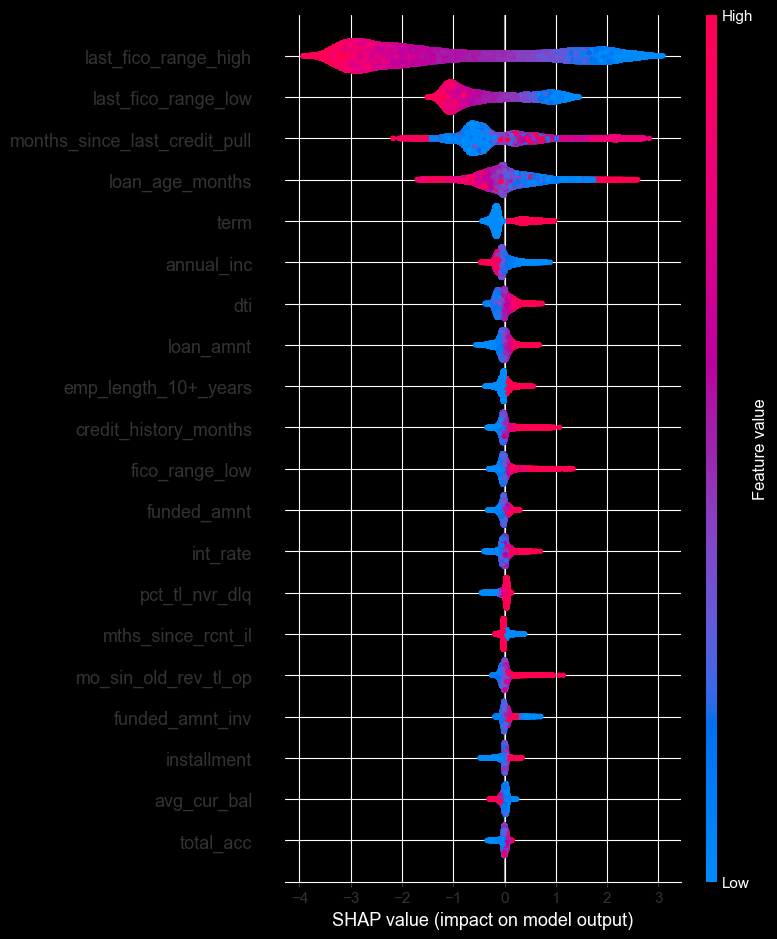

In [7]:
shap.summary_plot(shap_values, X)

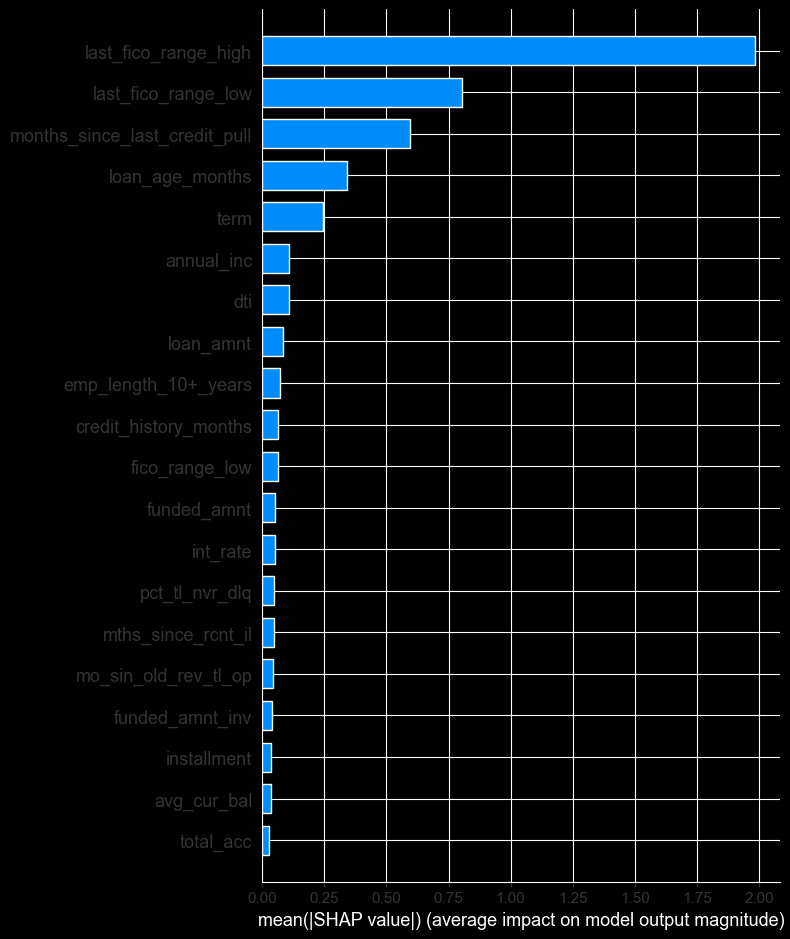

In [8]:
shap.summary_plot(shap_values, X, plot_type="bar")

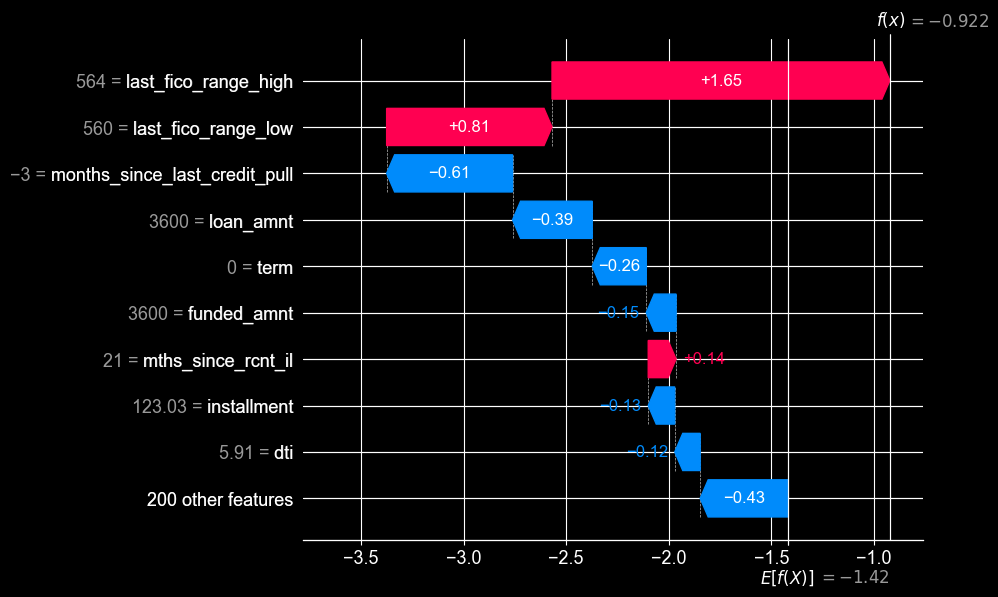

In [10]:
shap.plots.waterfall(shap.Explanation(
    values=shap_values[0],
    base_values=explainer.expected_value,
    data=sample,
    feature_names=X.columns
))

In [11]:
df.shape

(1345310, 210)